In [1]:
import baltic as bt
import pandas as pd
import json
import os
import matplotlib as mpl
from matplotlib import pyplot as plt
import requests
from io import StringIO as sio
from matplotlib.patches import Patch
import matplotlib.ticker as ticker
import itertools
import re
import sys
import pprint
import statistics

In [2]:
def load_tree(nexusPath):
    mytree = bt.loadNexus(nexusPath, tip_regex='\|([0-9]{4}\-[0-9]{2}\-[0-9]{2})', absoluteTime=True, verbose=False) # your tip regex might have to change or you could convert you tree into a newick by deleting everything before the tree string lol
    return(mytree)

In [3]:
# Load tree
#nexusPath=f'./BEAST/continuous_phylogeography/results/2025-07-10_nov2021-2024_ha_contphyl_thorney/NAm_wild-aves_nov2021-2024_ha_contphyl_2025-07-10_MCC.tree' # your path here
nexusPath_1='./BEAST/continuous_phylogeography/results/2025-08-20_nov2021-2024_no-suliformes_ha_contphyl_thorney_redo/NAm_wild-aves_nov2021-2024_no-suliformes_ha_contphyl_2025-08-18_MCC.tree' 
#nexusPath_2 = "./BEAST/discrete_trait_analysis/results/2025-09-01_flyway-latitude-order_emptree-contphyl/NAm_wild-aves_nov2021-2024_no-suliformes_ha_emptree-contphyl_flyway-order-latgrp_MCC.tree"
#nexusPath_3 = "./BEAST/empirical_trees/results/2025-08-07_nov2021-2024_no-suliformes_ha_empirical_thorney/NAm_wild-aves_nov2021-2024_no-suliformes_ha_empirical_thorney_2025-08-11_MCC.tree"

In [4]:
# Load continuous phylogeography tree
contphyltree = load_tree(nexusPath_1)
# Load DTA tree
#dtatree = load_tree(nexusPath_2)
# Load Empirical tree
#emptree = load_tree(nexusPath_3)

In [40]:
# Now many nodes and leaves is your tree

print(len(contphyltree.Objects))
print(len(dtatree.Objects))
print(len(emptree.Objects))

contphyltree.treeStats()
dtatree.treeStats()
emptree.treeStats()

10995
10995
10995

Tree height: 3.325378
Tree length: 696.371663
strictly bifurcating tree
annotations present

Numbers of objects in tree: 10995 (5497 nodes and 5498 leaves)


Tree height: 3.358283
Tree length: 697.435050
strictly bifurcating tree
annotations present

Numbers of objects in tree: 10995 (5497 nodes and 5498 leaves)


Tree height: 3.310616
Tree length: 694.666258
strictly bifurcating tree
annotations present

Numbers of objects in tree: 10995 (5497 nodes and 5498 leaves)



In [1]:
# What objects are included in the tree

print(dir(mytree.Objects[0].traits))

NameError: name 'mytree' is not defined

In [173]:
# This allows me to explore the tree a bit
# Change k.index and k, 'parent' to explore the objects for each item

for k in mytree2.Objects[:3]:
    print(f"{k.index}: {getattr(k, 'is_node')}")

0: <bound method node.is_node of <baltic.baltic.node object at 0x35078d610>>
1: <bound method node.is_node of <baltic.baltic.node object at 0x3507c8910>>
2: <bound method node.is_node of <baltic.baltic.node object at 0x351aff150>>


In [130]:
# TipMap is a list of tip names and their associated numbers
print(type(mytree2.tipMap))

<class 'dict'>


In [133]:
# This prints all of the leaf names in the tree

# for k in mytree2.getExternal(): ## iterate through leaf objects in tree
#     print(k.name)

In [5]:
# Set a flyway attribute for each leaf

# Turn tipMap into a dataframe
tipMap_df = pd.DataFrame.from_dict(contphyltree.tipMap, orient='index', columns=['leaf_name'])
#tipMap_df = pd.DataFrame.from_dict(dtatree.tipMap, orient='index', columns=['leaf_name'])
#tipMap_df = pd.DataFrame.from_dict(emptree.tipMap, orient='index', columns=['leaf_name'])
print(len(tipMap_df))

# Add a column for flyway
tipMap_df_upt = tipMap_df.copy()
tipMap_df_upt["NAflyway"] = tipMap_df_upt["leaf_name"].str.split("|", expand = True)[4]
print(tipMap_df_upt["NAflyway"].value_counts())

# Turn tipMap_df_upt back into a dictionary
tipMap_upt = tipMap_df_upt.to_dict(orient='index')

# Switch around the dictionary
name_to_flyway = {v['leaf_name']: v['NAflyway'] for v in tipMap_upt.values()}

5498
NAflyway
AtlanticFlyway       1513
MississippiFlyway    1458
CentralFlyway        1276
PacificFlyway        1251
Name: count, dtype: int64


In [6]:
# Set a flyway attribute for each leaf

# Turn tipMap into a dataframe
tipMap_df = pd.DataFrame.from_dict(contphyltree.tipMap, orient='index', columns=['leaf_name'])
#tipMap_df = pd.DataFrame.from_dict(dtatree.tipMap, orient='index', columns=['leaf_name'])
#tipMap_df = pd.DataFrame.from_dict(emptree.tipMap, orient='index', columns=['leaf_name'])
print(len(tipMap_df))

# Add a column for flyway
tipMap_df_upt = tipMap_df.copy()
tipMap_df_upt["bird_order"] = tipMap_df_upt["leaf_name"].str.split("|", expand = True)[3]
print(tipMap_df_upt["bird_order"].value_counts())

# # Turn tipMap_df_upt back into a dictionary
tipMap_upt = tipMap_df_upt.to_dict(orient='index')

# # Switch around the dictionary
name_to_flyway = {v['leaf_name']: v['bird_order'] for v in tipMap_upt.values()}

5498
bird_order
anseriformes        2602
accipitriformes     1471
strigiformes         434
passeriformes        314
charadriiformes      275
pelecaniformes       145
falconiformes         86
suliformes            61
podicipediformes      56
galliformes           18
columbiformes         13
gruiformes            10
gaviiformes            6
ciconiiformes          2
apodiformes            2
unknown                2
casuariiformes         1
Name: count, dtype: int64


In [7]:
#Test that tree is loaded
# for k in mytree.Objects:
    # if k.name == "NODE_0004247":
    #     print(k.traits)
        
    # # Use get() at each level to avoid KeyErrors if any key is missing
    # value = k.traits.get("node_attrs", {}).get("NAflyway", {}).get("value")
    # #value = k.traits.get("node_attrs", {}).get("bird_order", {}).get("value")
    
    # # Check if value is ever "unknown"
    # if not value:
    #     print(k.name)

In [8]:
flyway_colors = {
    "AtlanticFlyway":"#AA7722",
    "MississippiFlyway":"#5E9B82",
    "CentralFlyway":"#C593D1",
    "PacificFlyway":"#2B57B3"
}

In [7]:
flyway_colors = {"accipitriformes":"#C593D1",
               "strigiformes":"#C593D1", 
               "anseriformes":"#2B57B3",
               "charadriiformes":"#AA7722",
               "pelecaniformes":"#AA7722",
               "passeriformes":"#5E9B82",
               "falconiformes":"#5E9B82",
               "suliformes":"#5E9B82",
               "podicipediformes":"#5E9B82",
               "galliformes":"#5E9B82",
               "columbiformes":"#5E9B82",
               "gruiformes":"#5E9B82",
               "gaviiformes":"#5E9B82",
               "ciconiiformes":"#5E9B82",
               "apodiformes":"#5E9B82",
               "unknown":"#5E9B82",
               "casuariiformes":"#5E9B82",
               "other":"#5E9B82"
              }

In [8]:
def plot_nexus(mytree, save_path):

    plt.rcParams["font.family"] = "Arial"

    fig,ax = plt.subplots(figsize=(10,20),facecolor='w')
    
    #kwargs={'size': 20} ## kwargs for text
    
    x_attr=lambda k: k.absoluteTime
    
    # print(k)
        
    # Set the color-by (old function)
    # default color D1E2F0                                 
    # def color_by(k):
    #     flyway = tipMap_upt.get(k.index, {}).get("NAflyway")
    #     # order = k.traits.get("node_attrs", {}).get("NAflyway", {}).get("value")
    #     return flyway_colors.get(flyway, "#D1E2F0")

    for k in mytree.getExternal(): # Extract the flyway for each tip name using the name_to_flyway dictionary
        flyway = name_to_flyway.get(k.name, None)  # None if no match
        k.flyway = flyway

    def color_by(k): # New color-by function (why? because this is a cont phyl, not a DTA, so I can only color the tips because only the locations of nodes are inferred)
        if hasattr(k, 'flyway') and k.flyway in flyway_colors:
            return flyway_colors[k.flyway]
        return '#898989'  # default color
    
    mytree.plotTree(ax,x_attr=x_attr, colour=color_by) ## tree
    mytree.plotPoints(ax,
                      x_attr=x_attr,
                      size=30,
                      colour=color_by,
                      zorder=100)
    ax.plot() ## need to call plot when only drawing the tree to force drawing of line collections

    # # # If you want tree annotations
    # # # target_func=lambda k: k.is_leaf() ## which branches will be annotated
    # # # text_func=lambda k: k.traits['rea'] if k.traits['is_reassorted'] else "" ## what text is plotted
    # # # text_x_attr=lambda k: k.x+0.003 ## where x coordinate for text is
    # # # mytree.addText(ax,x_attr=text_x_attr,target=target_func,text=text_func, size='10')

    # If you want the legend in the tree
    legend_handles = [Patch(color=color, label=NAflyway) for NAflyway, color in flyway_colors.items()]
    legend = ax.legend(handles=legend_handles, title="$\\bf{Flyway}$", loc="center right", fontsize='15')
    plt.setp(legend.get_title(),fontsize=25)

    # # # If you want a scale bar
    # # # scale_length = 0.01
    # # # x_min, x_max = ax.get_xlim()
    # # # scale_x_start = x_min + (x_max - x_min) * 0.1
    # # # scale_x_end = scale_x_start + scale_length * (x_max - x_min)
    # # # scale_y = 0.05 * (ax.get_ylim()[1] - ax.get_ylim()[0]) + ax.get_ylim()[0]
    
    # ax.plot([scale_x_start, scale_x_end], [scale_y, scale_y], color='black', lw=2)
    # ax.text((scale_x_start + scale_x_end) / 2, scale_y, f'{scale_length}', 
    #         ha='center', va='bottom', fontsize=15)
    
    ax.set_yticks([])
    ax.set_yticklabels([])
    [ax.spines[loc].set_visible(False) for loc in ax.spines if loc not in ['bottom']]
    ax.tick_params(axis='x',labelsize=10,size=15, width=2,color='grey')
    fig.tight_layout()
    plt.savefig(save_path)
    plt.show()

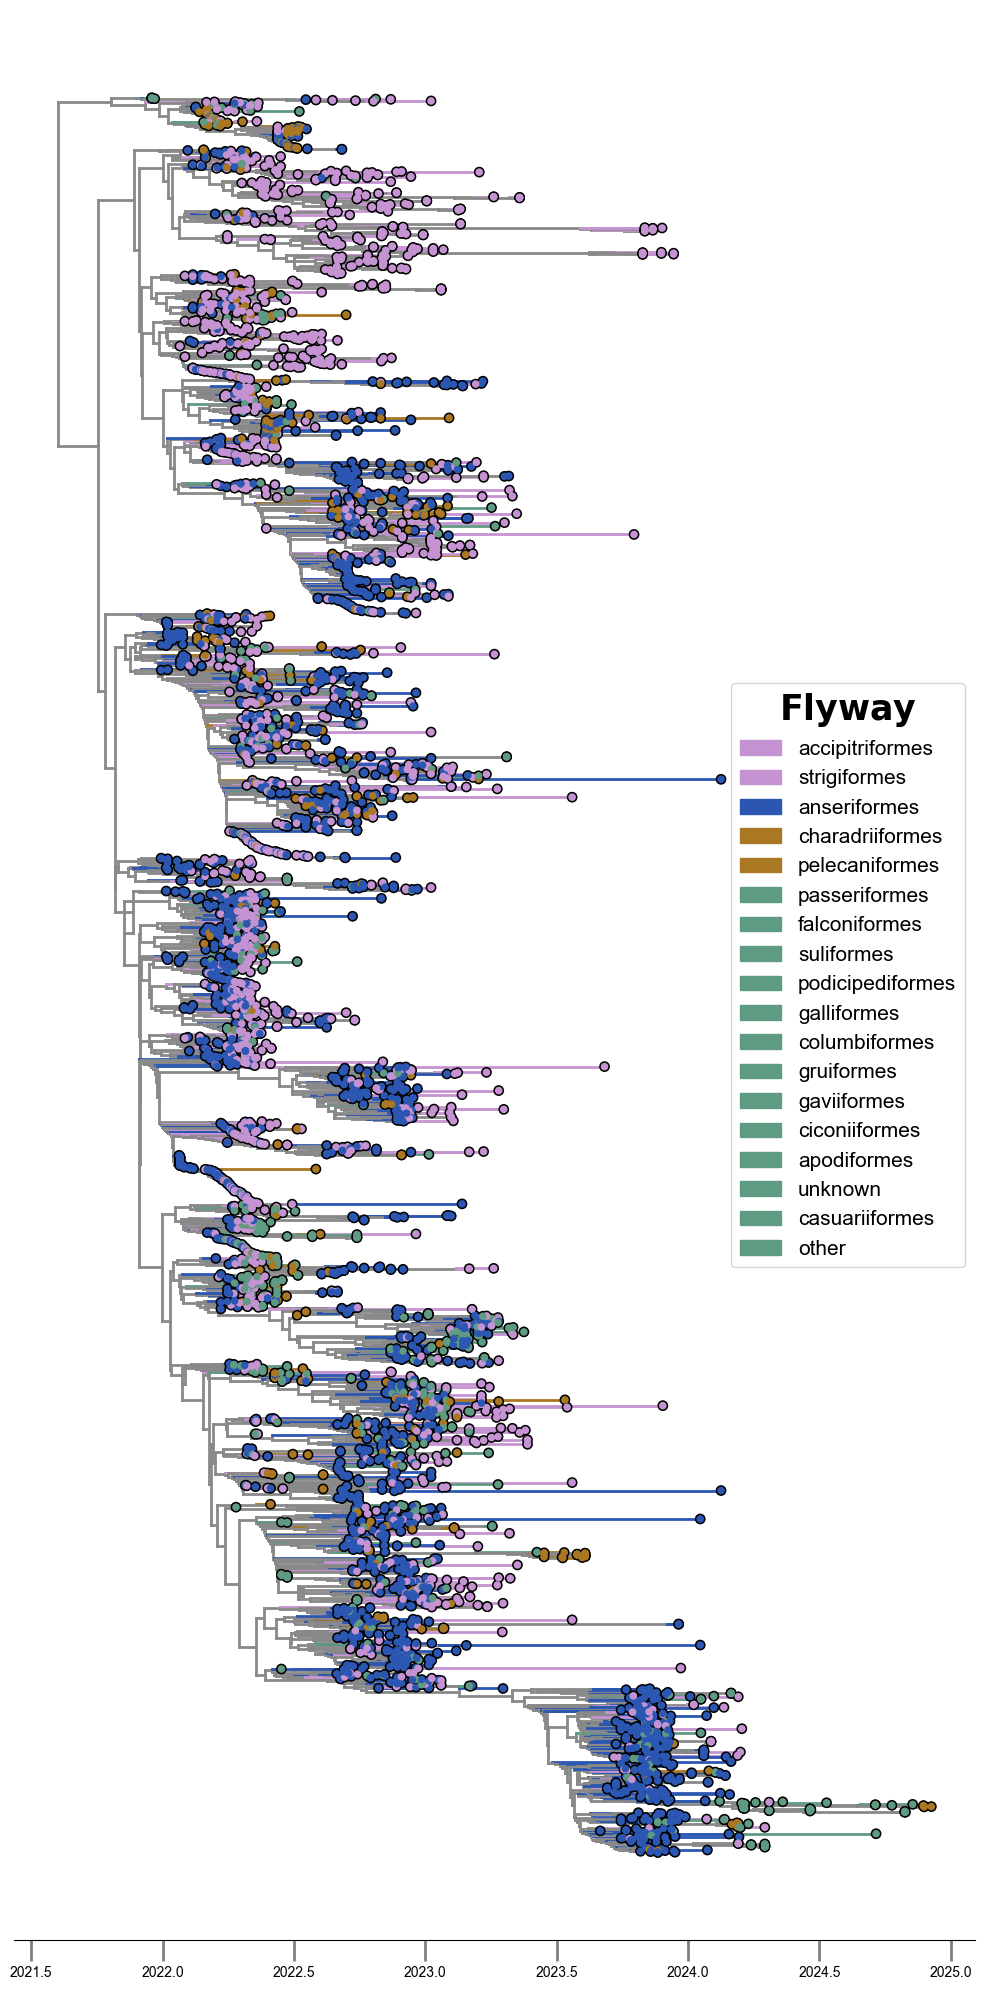

In [9]:
plot_nexus(contphyltree, "./BEAST/continuous_phylogeography/results/2025-08-20_nov2021-2024_no-suliformes_ha_contphyl_thorney_redo/NAm_wild-aves_nov2021-2024_no-suliformes_ha_contphyl_2025-08-18_MCC-baltic_althostcolors.pdf")

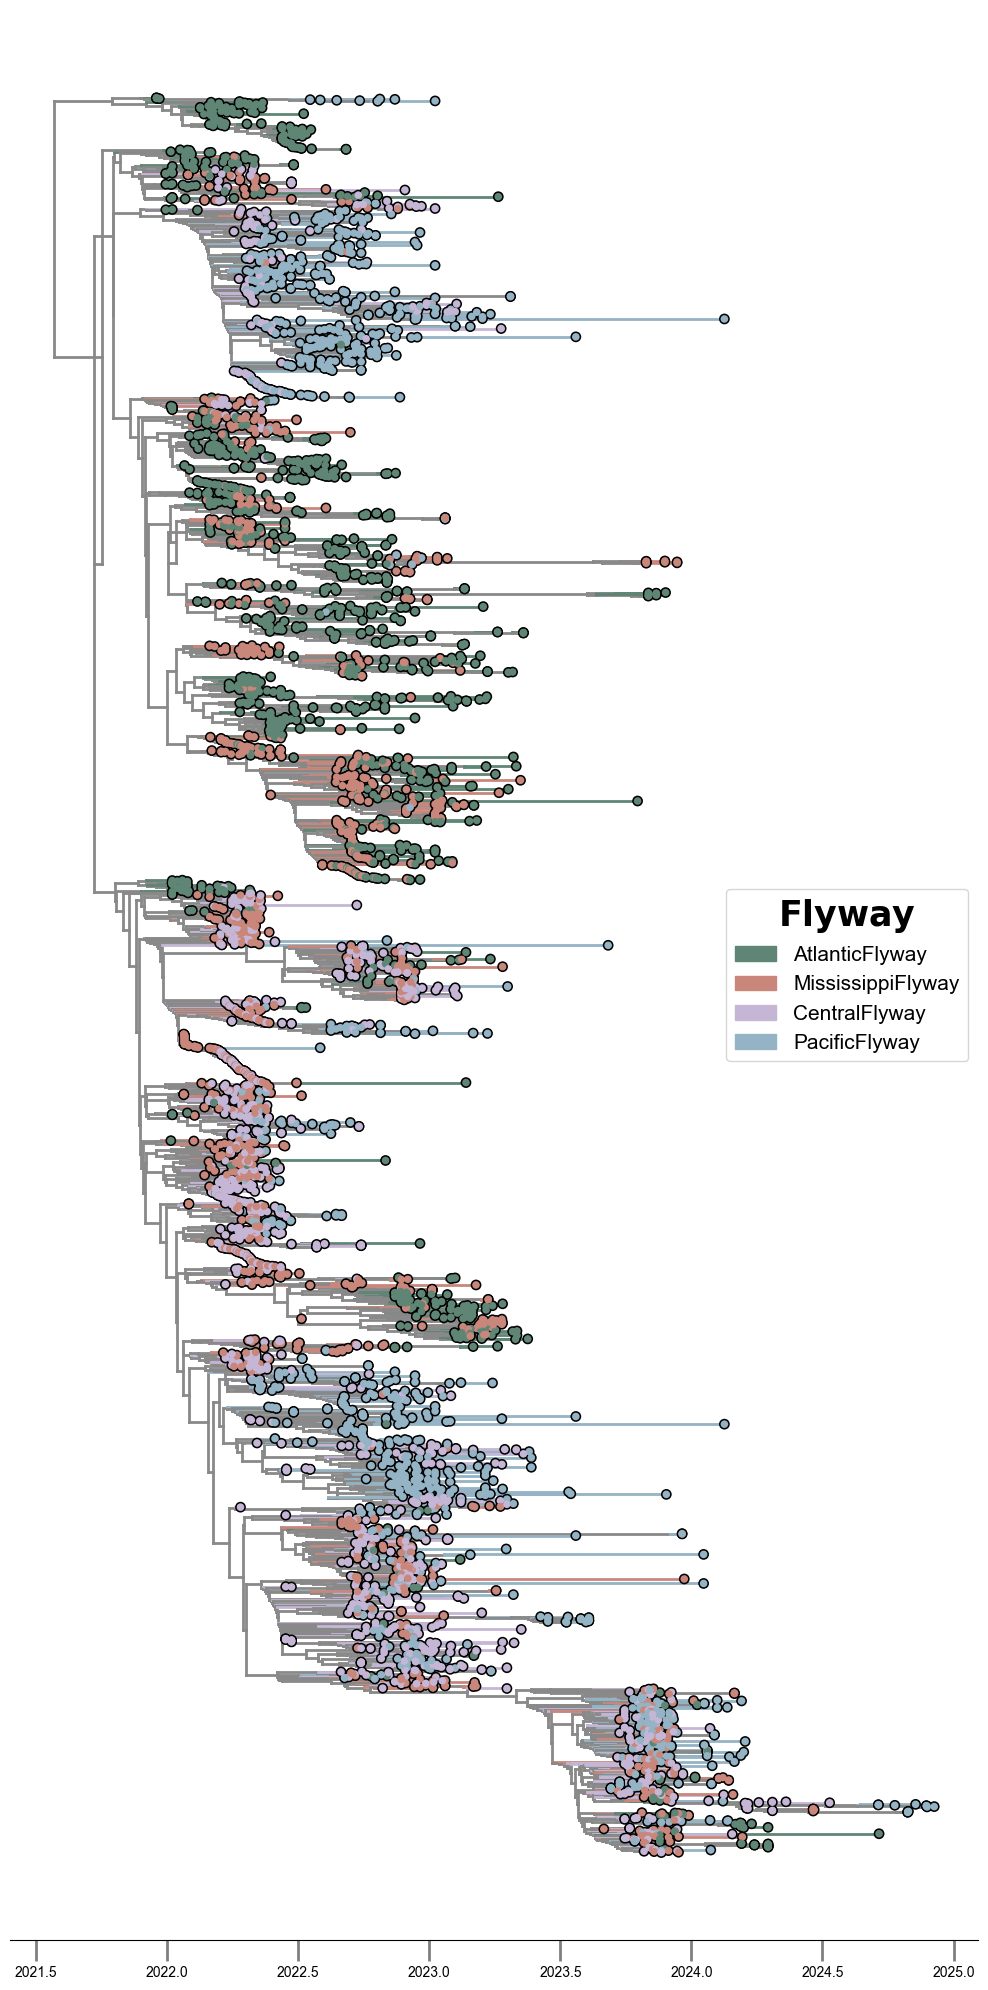

In [36]:
plot_nexus(dtatree, "./BEAST/discrete_trait_analysis/results/2025-09-01_flyway-latitude-order_emptree-contphyl/NAm_wild-aves_nov2021-2024_no-suliformes_ha_flyway-order-latgrp_2025-09-01_MCC-baltic.pdf")

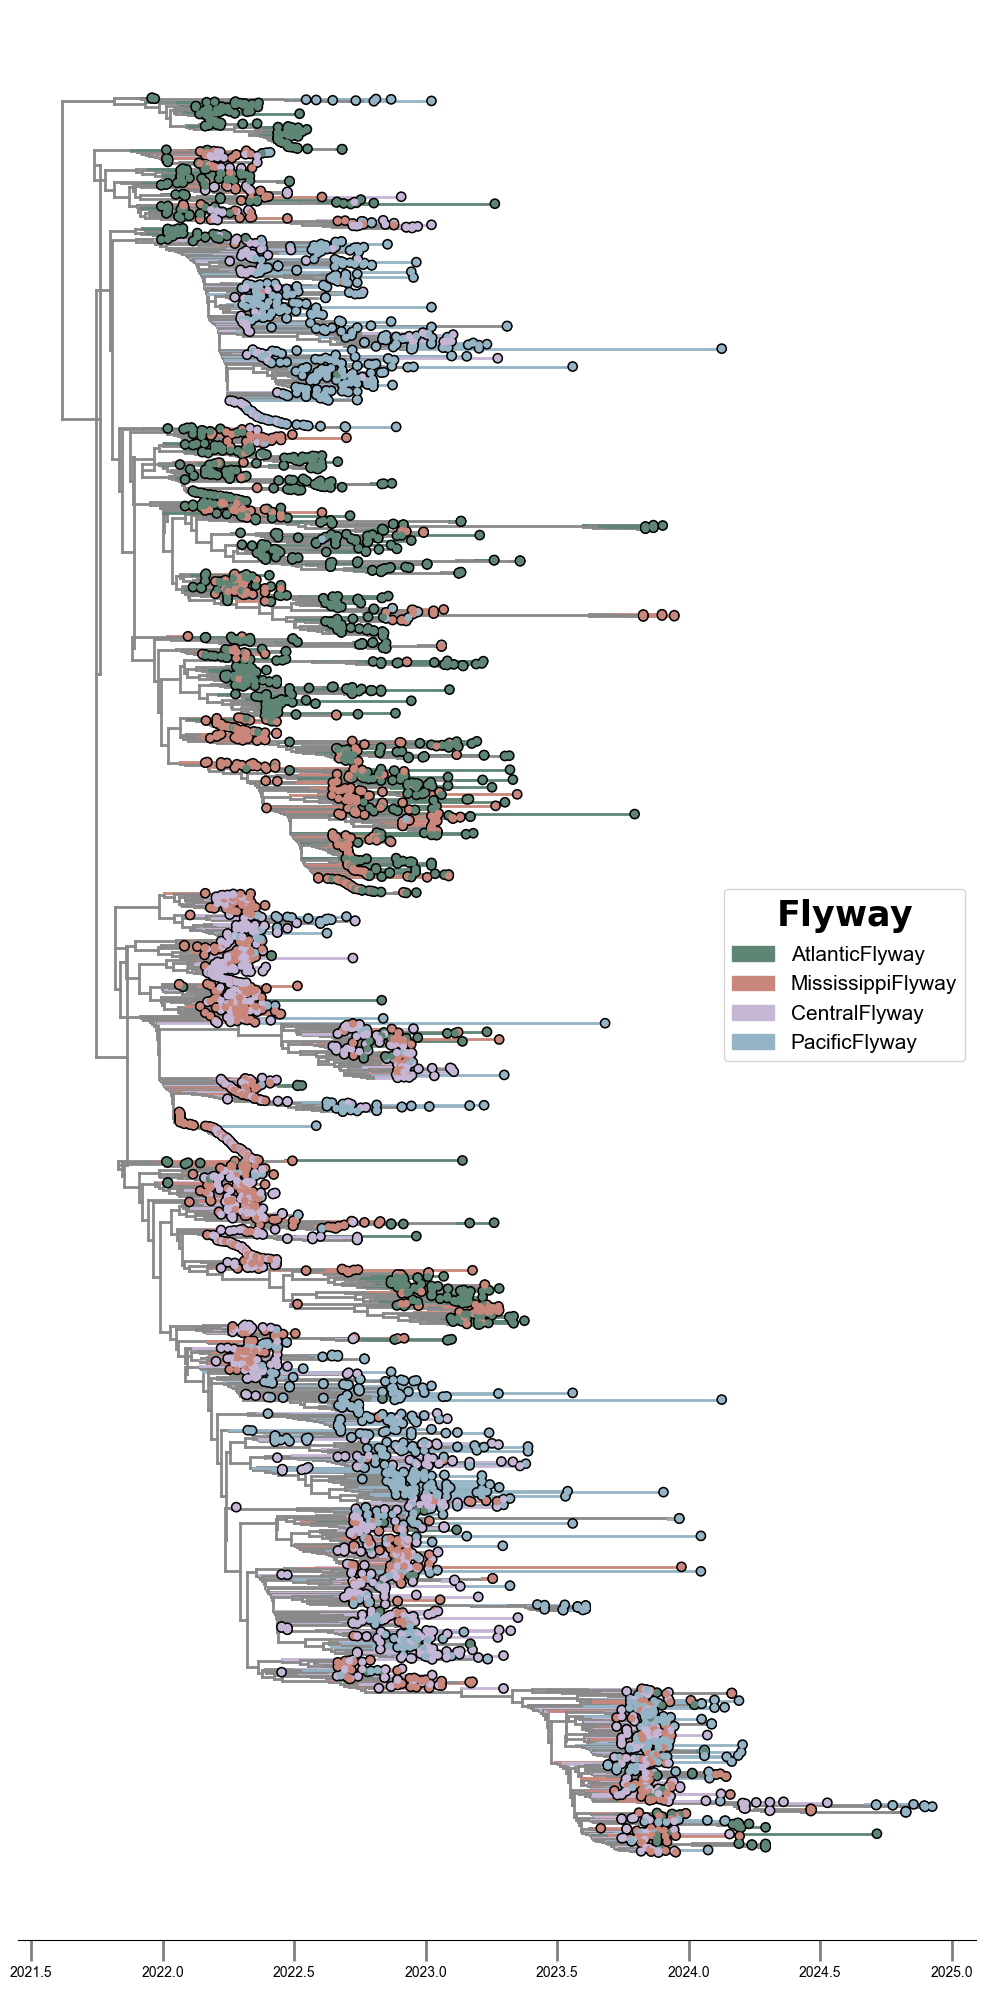

In [42]:
plot_nexus(emptree, "./BEAST/empirical_trees/results/2025-08-07_nov2021-2024_no-suliformes_ha_empirical_thorney/NAm_wild-aves_nov2021-2024_no-suliformes_ha_empirical_thorney_2025-08-07_MCC.pdf")

In [ ]:
# If you want a separate legend

fig, ax = plt.subplots(figsize=(15, 15))

legend_handles = [Patch(color=color, label=bird_order) for bird_order, color in host_order.items()]

legend = ax.legend(handles=legend_handles, title="$\\bf{Host Order}$", loc="center right", fontsize='15')
plt.setp(legend.get_title(),fontsize=20)

plt.show()
plt.savefig("./Nextstrain/2025-02-24_NAm_aves-wild_division_nopacific_countypriority/hostcolor_legend.pdf")

In [ ]:
# Plot number of transitions in a DTA